# Machine Learning-Based Organic Farming Suitability Prediction

**Project Based Learning (PBL) — Binary Classification**

This notebook builds a reproducible machine-learning workflow using the supplied 1,000-row dataset. Run all cells from top to bottom.

> **Important dataset limitation:** The README identifies this as *source-calibrated synthetic data* prepared for educational/PBL purposes. It is **not** 1,000 authentic field or laboratory observations. The suitability label is created using an instructional rubric, not an official organic-farming certification or legal standard. Do not present model results as validated real-world agronomic performance.

## Project objectives
1. Understand the data and inspect quality.
2. Perform EDA and visualizations.
3. Preprocess numerical and categorical variables.
4. Train and compare Logistic Regression, Decision Tree, Random Forest and KNN.
5. Evaluate using accuracy, precision, recall, F1-score, confusion matrix and ROC-AUC.
6. Interpret influential features and justify a model.

**Leakage prevention:** `Suitability_Score` is excluded from model inputs because the README says it is derived from the same instructional rubric as the target label. `Sample_ID` is also excluded because it is only an identifier.


In [1]:
# 1. Import libraries and load the supplied dataset
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score,
    RocCurveDisplay
)
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
DATA_FILE = "organic_farming_suitability_1000_source_calibrated.csv"

df = pd.read_csv(DATA_FILE)
print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (1000, 24)


,Sample_ID,State,Soil_Type,Crop,pH,Organic_Carbon_pct,Available_N_kg_ha,Available_P_kg_ha,Available_K_kg_ha,Available_S_mg_kg,Available_Zn_mg_kg,Available_Fe_mg_kg,Available_Mn_mg_kg,Available_Cu_mg_kg,Available_B_mg_kg,EC_dS_m,Annual_Rainfall_mm,Mean_Temperature_C,Soil_Moisture_pct,Previous_Fertilizer_Usage,Previous_Pesticide_Usage,Years_Chemical_Input,Suitability_Score,Organic_Farming_Suitability
0,OF-0001,Haryana,Sandy,Tomato,6.13,0.411,80.0,65.2,266.9,15.71,0.33,7.18,20.76,1.43,0.29,0.191,954.2,26.5,17.9,Mixed,Low,0,39.1,Not Suitable
1,OF-0002,Andhra Pradesh,Loamy,Sugarcane,7.58,0.826,187.8,29.4,131.5,13.64,0.66,5.77,11.35,0.71,0.65,0.652,841.9,30.7,33.6,Chemical,Moderate,8,53.0,Not Suitable
2,OF-0003,Karnataka,Loamy,Pulses,6.00,0.684,353.4,3.0,351.5,20.35,0.81,31.86,30.98,0.72,0.48,0.317,562.3,23.0,30.6,Chemical,Moderate,12,45.2,Not Suitable
3,OF-0004,Madhya Pradesh,Red,Pulses,6.69,0.706,200.3,39.0,61.7,10.96,0.95,16.30,5.20,0.73,2.51,0.323,741.1,26.8,33.5,Chemical,Moderate,8,44.7,Not Suitable
4,OF-0005,Madhya Pradesh,Red,Sugarcane,6.46,1.564,181.3,11.7,411.4,14.66,0.64,8.88,3.03,0.72,0.65,0.512,870.0,25.0,24.3,Chemical,High,2,52.6,Not Suitable


## 2. Understand the dataset
The target is `Organic_Farming_Suitability`. The input columns describe crop, soil, environmental conditions and previous input-management history. `Suitability_Score` is retained for descriptive inspection only, not prediction.

In [2]:
# 2.1 Structure, types, summary and data quality
display(df.info())
display(df.describe(include="all").T)
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print("\nTarget counts:")
display(df["Organic_Farming_Suitability"].value_counts())
print("\nTarget proportions:")
display((df["Organic_Farming_Suitability"].value_counts(normalize=True) * 100).round(2))


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 24 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Sample_ID                    1000 non-null   object 
 1   State                        1000 non-null   object 
 2   Soil_Type                    1000 non-null   object 
 3   Crop                         1000 non-null   object 
 4   pH                           1000 non-null   float64
 5   Organic_Carbon_pct           1000 non-null   float64
 6   Available_N_kg_ha            1000 non-null   float64
 7   Available_P_kg_ha            1000 non-null   float64
 8   Available_K_kg_ha            1000 non-null   float64
 9   Available_S_mg_kg            1000 non-null   float64
 10  Available_Zn_mg_kg           1000 non-null   float64
 11  Available_Fe_mg_kg           1000 non-null   float64
 12  Available_Mn_mg_kg           1000 non-null   float64
 13  Available_Cu_mg_kg 

None

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Sample_ID,1000,1000,OF-0001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
State,1000,15,Madhya Pradesh,81,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Soil_Type,1000,7,Alluvial,279,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Crop,1000,12,Maize,110,NaN,NaN,NaN,NaN,NaN,NaN,NaN
pH,1000.0,NaN,NaN,NaN,6.91594,0.754045,4.8,6.4,6.925,7.42,9.19
Organic_Carbon_pct,1000.0,NaN,NaN,NaN,0.724501,0.346696,0.189,0.481,0.6535,0.87725,2.5
Available_N_kg_ha,1000.0,NaN,NaN,NaN,259.0167,91.347824,80.0,194.075,257.3,315.825,588.1
Available_P_kg_ha,1000.0,NaN,NaN,NaN,29.5494,16.859065,3.0,16.475,29.1,40.825,86.3
Available_K_kg_ha,1000.0,NaN,NaN,NaN,254.2527,126.79943,40.0,165.7,242.35,345.925,653.2
Available_S_mg_kg,1000.0,NaN,NaN,NaN,15.80129,6.615834,3.0,11.2825,15.54,20.2575,39.06


Missing values: 0
Duplicate rows: 0

Target counts:


Organic_Farming_Suitability
Not Suitable    577
Suitable        423
Name: count, dtype: int64


Target proportions:


Organic_Farming_Suitability
Not Suitable    57.7
Suitable        42.3
Name: proportion, dtype: float64

## 3. Exploratory Data Analysis (EDA)
The following charts summarize class balance, selected numeric distributions, numeric correlations and class-wise differences. These are descriptive patterns in this synthetic teaching dataset, not causal evidence.

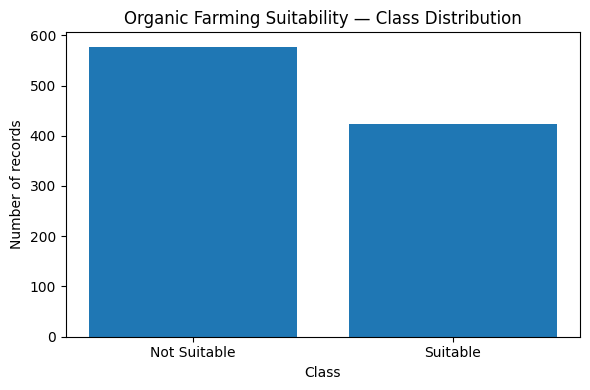

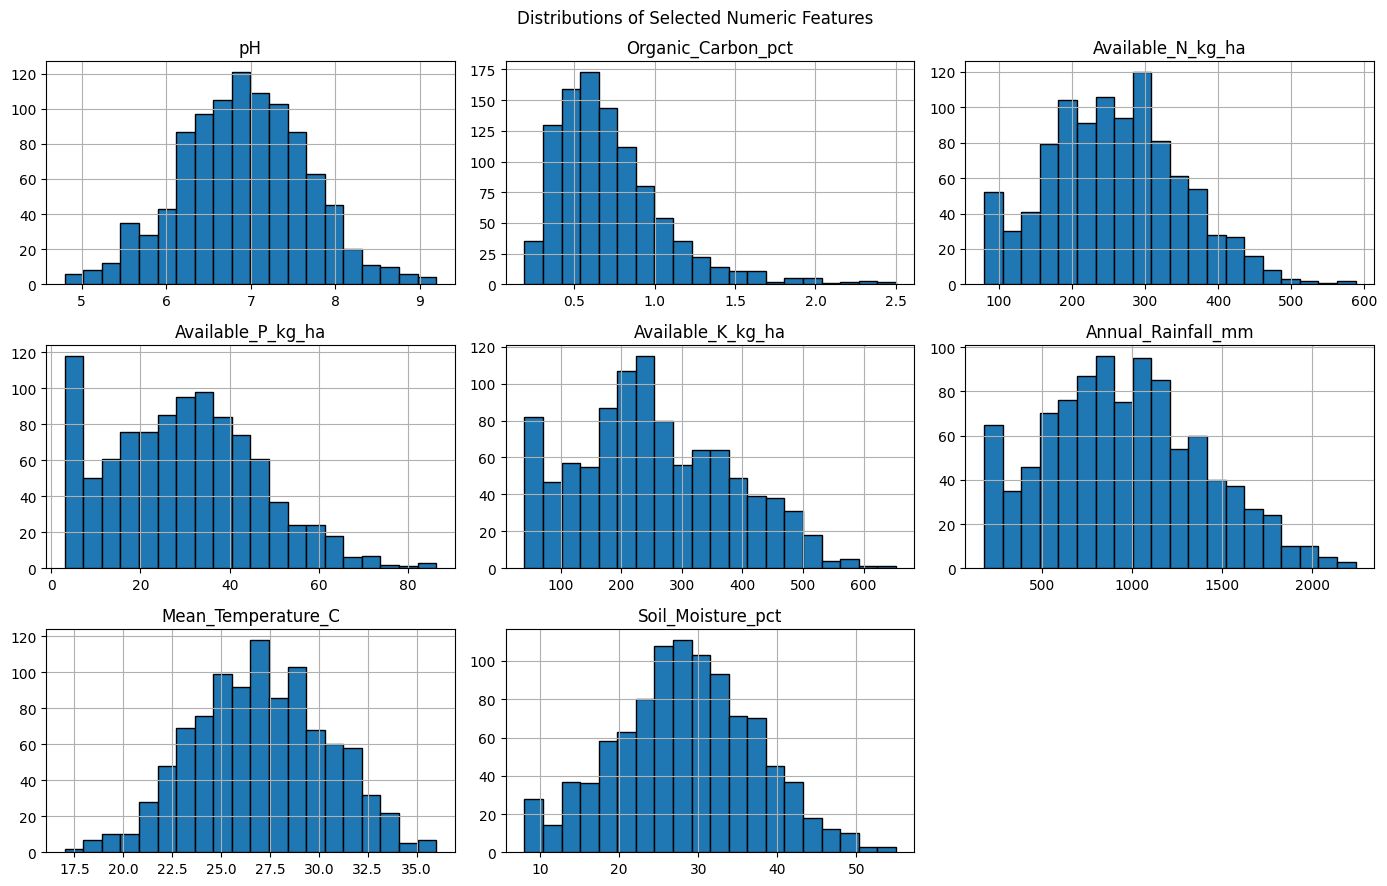

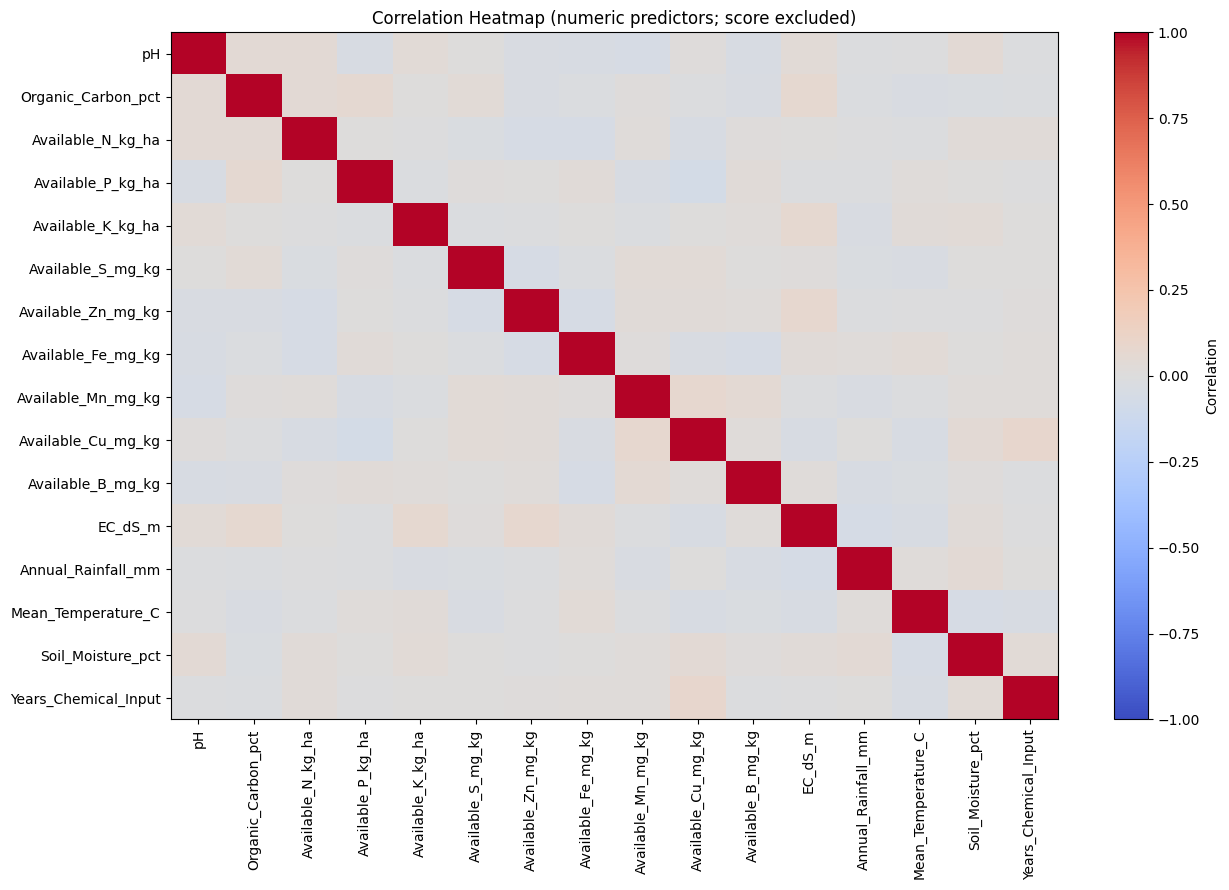

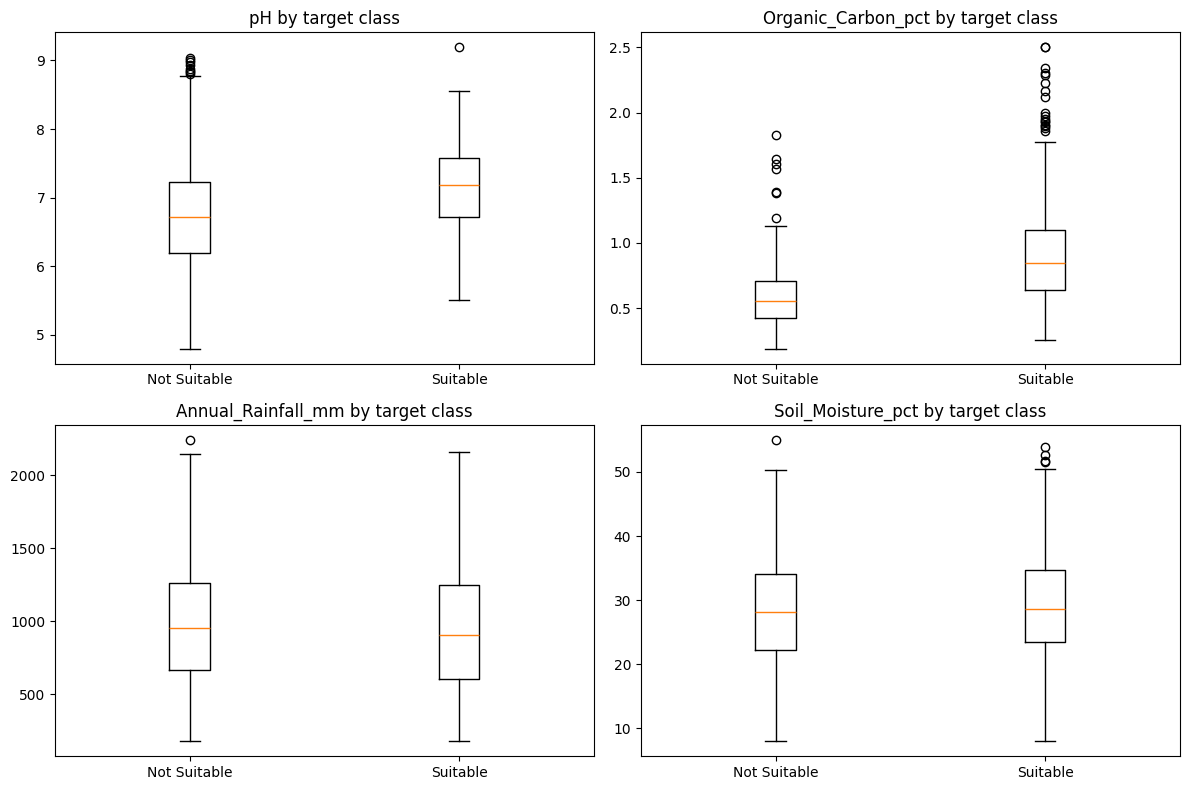

In [3]:
# 3.1 Target class distribution
counts = df["Organic_Farming_Suitability"].value_counts().reindex(["Not Suitable", "Suitable"])
plt.figure(figsize=(6,4))
plt.bar(counts.index, counts.values)
plt.title("Organic Farming Suitability — Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()

# 3.2 Numeric feature distributions
numeric_for_eda = ["pH", "Organic_Carbon_pct", "Available_N_kg_ha",
                   "Available_P_kg_ha", "Available_K_kg_ha",
                   "Annual_Rainfall_mm", "Mean_Temperature_C", "Soil_Moisture_pct"]
df[numeric_for_eda].hist(figsize=(14,9), bins=20, edgecolor="black")
plt.suptitle("Distributions of Selected Numeric Features")
plt.tight_layout()
plt.show()

# 3.3 Correlation heatmap
corr = df.select_dtypes(include=np.number).drop(columns=["Suitability_Score"], errors="ignore").corr()
plt.figure(figsize=(13,9))
plt.imshow(corr, cmap="coolwarm", aspect="auto", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.title("Correlation Heatmap (numeric predictors; score excluded)")
plt.tight_layout()
plt.show()

# 3.4 Feature comparisons by target class
fig, axes = plt.subplots(2, 2, figsize=(12,8))
for ax, col in zip(axes.flat, ["pH", "Organic_Carbon_pct", "Annual_Rainfall_mm", "Soil_Moisture_pct"]):
    values = [df.loc[df["Organic_Farming_Suitability"] == label, col].dropna() for label in ["Not Suitable", "Suitable"]]
    ax.boxplot(values, labels=["Not Suitable", "Suitable"])
    ax.set_title(f"{col} by target class")
plt.tight_layout()
plt.show()


## 4. Data preprocessing and feature selection

- Drop `Sample_ID` (identifier) and `Suitability_Score` (potential target leakage).
- Keep crop, soil type, state and prior input usage as categorical predictors.
- Impute missing numerical values with the median and categorical values with the most frequent value.
- One-hot encode categorical variables.
- Standardize numeric variables (important for Logistic Regression and KNN).
- Split data into training and test sets using stratification to preserve class proportions.

No rows are removed simply because they are unusual; the dataset is checked first and preprocessing is performed inside each model pipeline to avoid leakage from the test set.


In [4]:
# 4.1 Separate target and predictors
target = "Organic_Farming_Suitability"
drop_columns = ["Sample_ID", "Suitability_Score", target]
X = df.drop(columns=drop_columns)
y = (df[target] == "Suitable").astype(int)  # Positive class = Suitable

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Positive class (1): Suitable")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Training rows:", len(X_train), "| Test rows:", len(X_test))

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])


Numeric features: ['pH', 'Organic_Carbon_pct', 'Available_N_kg_ha', 'Available_P_kg_ha', 'Available_K_kg_ha', 'Available_S_mg_kg', 'Available_Zn_mg_kg', 'Available_Fe_mg_kg', 'Available_Mn_mg_kg', 'Available_Cu_mg_kg', 'Available_B_mg_kg', 'EC_dS_m', 'Annual_Rainfall_mm', 'Mean_Temperature_C', 'Soil_Moisture_pct', 'Years_Chemical_Input']
Categorical features: ['State', 'Soil_Type', 'Crop', 'Previous_Fertilizer_Usage', 'Previous_Pesticide_Usage']
Positive class (1): Suitable
Training rows: 800 | Test rows: 200


## 5. Train and compare classification models
All models use the same train/test split and preprocessing pipeline. The test set is held out from model fitting.

In [5]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE, min_samples_leaf=3),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE,
                                            class_weight="balanced", min_samples_leaf=2),
    "KNN": KNeighborsClassifier(n_neighbors=7)
}

pipelines = {}
results = []
for name, estimator in models.items():
    pipe = Pipeline(steps=[("preprocessor", preprocessor), ("model", estimator)])
    pipe.fit(X_train, y_train)
    pipelines[name] = pipe
    pred = pipe.predict(X_test)
    prob = pipe.predict_proba(X_test)[:, 1]
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1-score": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, prob)
    })

results_df = pd.DataFrame(results).sort_values("F1-score", ascending=False).reset_index(drop=True)
display(results_df.round(4))


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.805,0.7875,0.7412,0.7636,0.8891
1,Random Forest,0.795,0.7750,0.7294,0.7515,0.8950
2,Decision Tree,0.780,0.7531,0.7176,0.7349,0.7903
3,KNN,0.770,0.7600,0.6706,0.7125,0.8291


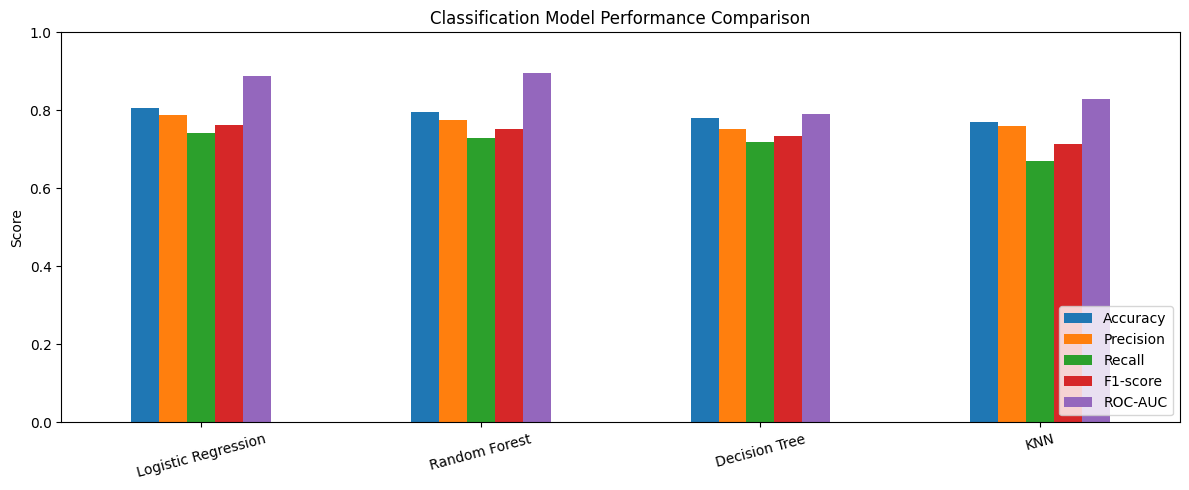

In [6]:
# 5.1 Compare model metrics visually
plot_df = results_df.set_index("Model")[["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]]
plot_df.plot(kind="bar", figsize=(12,5), ylim=(0,1), rot=15)
plt.title("Classification Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


## 6. Detailed evaluation of the selected model
The model with the highest test F1-score is selected. F1 balances precision and recall; ROC-AUC measures ranking ability across thresholds. The best model is selected based on this held-out test comparison for this educational exercise.

Selected model: Logistic Regression

Classification report (1 = Suitable):
              precision    recall  f1-score   support

Not Suitable       0.82      0.85      0.83       115
    Suitable       0.79      0.74      0.76        85

    accuracy                           0.81       200
   macro avg       0.80      0.80      0.80       200
weighted avg       0.80      0.81      0.80       200



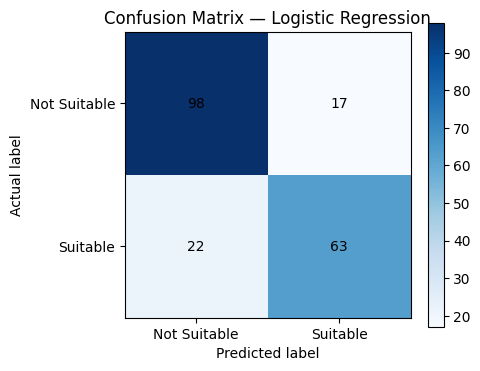

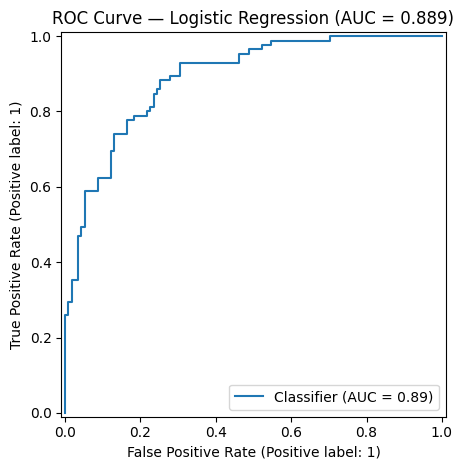

In [7]:
best_name = results_df.loc[0, "Model"]
best_model = pipelines[best_name]
best_pred = best_model.predict(X_test)
best_prob = best_model.predict_proba(X_test)[:, 1]

print("Selected model:", best_name)
print("\nClassification report (1 = Suitable):")
print(classification_report(y_test, best_pred, target_names=["Not Suitable", "Suitable"]))

cm = confusion_matrix(y_test, best_pred)
plt.figure(figsize=(5,4))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, str(cm[i, j]), ha="center", va="center")
plt.xticks([0, 1], ["Not Suitable", "Suitable"])
plt.yticks([0, 1], ["Not Suitable", "Suitable"])
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.title(f"Confusion Matrix — {best_name}")
plt.tight_layout()
plt.show()

RocCurveDisplay.from_predictions(y_test, best_prob)
plt.title(f"ROC Curve — {best_name} (AUC = {roc_auc_score(y_test, best_prob):.3f})")
plt.tight_layout()
plt.show()


## 7. Feature influence (permutation importance)

Permutation importance measures how much the selected model's F1-score falls when one original input column is shuffled. It works on the complete pipeline and therefore reports importance at the original feature level. It indicates predictive influence in this dataset, not causation or agronomic importance in the real world.


Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

,Feature,Mean importance (F1 decrease),Std
4,Organic_Carbon_pct,0.1977,0.0376
3,pH,0.0756,0.0311
6,Available_P_kg_ha,0.0678,0.0179
18,Previous_Fertilizer_Usage,0.0508,0.0204
5,Available_N_kg_ha,0.0445,0.0202
7,Available_K_kg_ha,0.0296,0.0119
19,Previous_Pesticide_Usage,0.0080,0.0186
0,State,0.0046,0.0094
2,Crop,0.0034,0.0123
17,Soil_Moisture_pct,0.0015,0.0030


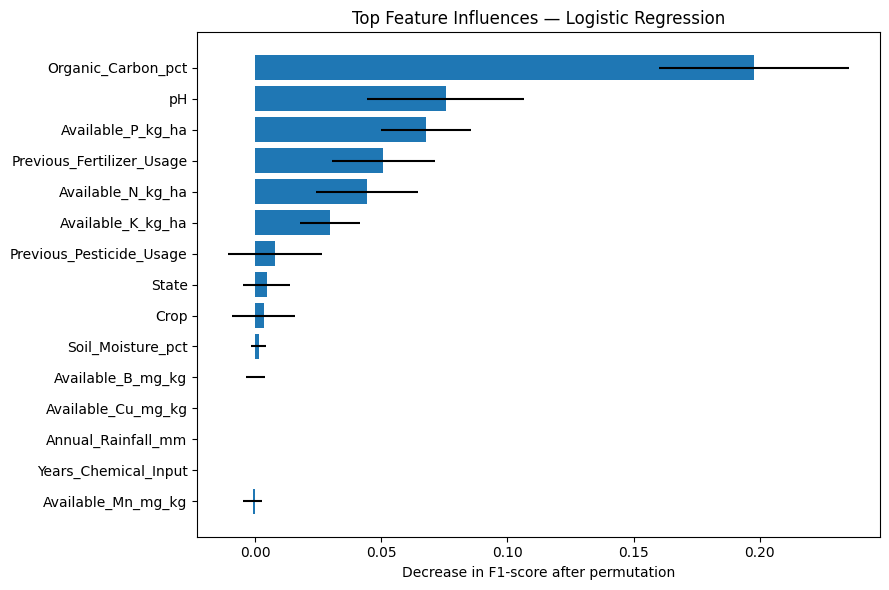

In [8]:
perm = permutation_importance(
    best_model, X_test, y_test, n_repeats=10, random_state=RANDOM_STATE,
    scoring="f1", n_jobs=-1
)
importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Mean importance (F1 decrease)": perm.importances_mean,
    "Std": perm.importances_std
}).sort_values("Mean importance (F1 decrease)", ascending=False)

display(importance_df.head(15).round(4))
top_imp = importance_df.head(15).sort_values("Mean importance (F1 decrease)")
plt.figure(figsize=(9,6))
plt.barh(top_imp["Feature"], top_imp["Mean importance (F1 decrease)"], xerr=top_imp["Std"])
plt.xlabel("Decrease in F1-score after permutation")
plt.title(f"Top Feature Influences — {best_name}")
plt.tight_layout()
plt.show()


## 8. Final project summary and limitations

The cell below prints the measured test metrics and the main methodological conclusions. Copy these actual outputs into the written report after running the notebook.

### Limitations to state in the report
1. The dataset is source-calibrated synthetic data created for teaching, not 1,000 genuine field/laboratory observations.
2. The target labels and suitability score come from an instructional rubric, not an official certification/legal standard.
3. High model scores, if obtained, show how well a model learns patterns in this generated dataset; they do not prove reliable performance on real farms.
4. The dataset contains only 1,000 instances. External validation on authentic, independently labelled field data is needed before practical use.
5. Feature importance is associational and model-dependent; it does not establish cause and effect.

### Conclusion template
The best model is selected by comparing Accuracy, Precision, Recall, F1-score and ROC-AUC on the held-out test set. The selected model and the top influential features are reported below. Any recommendation for actual organic farming must be confirmed by qualified agricultural experts and real field data.


In [9]:
print("PROJECT RESULT SUMMARY")
print("======================")
print("Dataset records:", len(df))
print("Features used:", X.shape[1])
print("Training / test split:", len(X_train), "/", len(X_test))
print("Best model by test F1-score:", best_name)
print("Best model metrics:")
display(results_df.iloc[[0]].round(4))
print("Top 5 influential features:")
display(importance_df.head(5).round(4))
print("\nDataset provenance: source-calibrated synthetic educational dataset.")
print("Target-label caveat: instructional rubric; not official organic certification.")


PROJECT RESULT SUMMARY
Dataset records: 1000
Features used: 21
Training / test split: 800 / 200
Best model by test F1-score: Logistic Regression
Best model metrics:


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.805,0.7875,0.7412,0.7636,0.8891


Top 5 influential features:


,Feature,Mean importance (F1 decrease),Std
4,Organic_Carbon_pct,0.1977,0.0376
3,pH,0.0756,0.0311
6,Available_P_kg_ha,0.0678,0.0179
18,Previous_Fertilizer_Usage,0.0508,0.0204
5,Available_N_kg_ha,0.0445,0.0202



Dataset provenance: source-calibrated synthetic educational dataset.
Target-label caveat: instructional rubric; not official organic certification.


## 9. Optional: predict one new crop–field example

Edit the values in the dictionary below to match the exact input columns. The example uses an existing row only to demonstrate the prediction interface; it is **not** a new real-world assessment.


In [10]:
# Demonstration using the first held-out row (replace with a genuinely new record when available)
example = X_test.iloc[[0]].copy()
predicted_class = best_model.predict(example)[0]
predicted_probability = best_model.predict_proba(example)[0, 1]
print("Predicted class:", "Suitable" if predicted_class == 1 else "Not Suitable")
print(f"Model probability for Suitable: {predicted_probability:.3f}")
print("Reminder: educational synthetic-data demonstration only.")


Predicted class: Suitable
Model probability for Suitable: 1.000
Reminder: educational synthetic-data demonstration only.
